<a href="https://colab.research.google.com/github/julianbarrycodes/clinical-trials-landscape/blob/main/fetch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Step 1 of the clinical trials landscape project:
fetch a small sample of trials from the ClinicalTrials.gov API (v2)
and look at what comes back.

Setup (once):
    pip install requests pandas

Run:
    python fetch_trials.py
"""

import requests
import pandas as pd

API_URL = "https://clinicaltrials.gov/api/v2/studies"

params = {
    "query.cond": "diabetes",  # try other conditions later, e.g. "obesity", "Alzheimer"
    "pageSize": 100,           # max 1000 per page
    "format": "json",
}

response = requests.get(API_URL, params=params, timeout=30)
response.raise_for_status()
studies = response.json().get("studies", [])

rows = []
for study in studies:
    ps = study.get("protocolSection", {})
    ident = ps.get("identificationModule", {})
    status = ps.get("statusModule", {})
    design = ps.get("designModule", {})
    sponsor = ps.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {})

    rows.append({
        "nct_id": ident.get("nctId"),
        "title": ident.get("briefTitle"),
        "status": status.get("overallStatus"),
        "phases": ", ".join(design.get("phases", [])),
        "study_type": design.get("studyType"),
        "sponsor": sponsor.get("name"),
        "sponsor_type": sponsor.get("class"),
        "start_date": status.get("startDateStruct", {}).get("date"),
    })

df = pd.DataFrame(rows)

print(f"Fetched {len(df)} trials\n")
print(df.head(10).to_string())
print("\nTrials by status:")
print(df["status"].value_counts())
print("\nTrials by phase:")
print(df["phases"].value_counts())

# Save so you can explore it later (Excel, Power BI, or more Python)
df.to_csv("trials_sample.csv", index=False)
print("\nSaved to trials_sample.csv")

Fetched 100 trials

        nct_id                                                                                                                  title      status  phases      study_type                                       sponsor sponsor_type  start_date
0  NCT03162237                                                                Safety and Efficacy Study of Islets Xenotransplantation   COMPLETED      NA  INTERVENTIONAL                                   Wei Wang,MD        OTHER     2013-07
1  NCT01121172                                                          Apelin Levels and G212A Polymorphism of Apelin Receptor (APJ)   COMPLETED           OBSERVATIONAL          Aristotle University Of Thessaloniki        OTHER     2010-05
2  NCT01630512  Mindfulness-Based Cognitive Therapy (MBCT) and Cognitive Behavioral Therapy (CBT) for Depression in Diabetes Patients   COMPLETED      NA  INTERVENTIONAL           University Medical Center Groningen        OTHER     2011-05
3  NCT01698112  

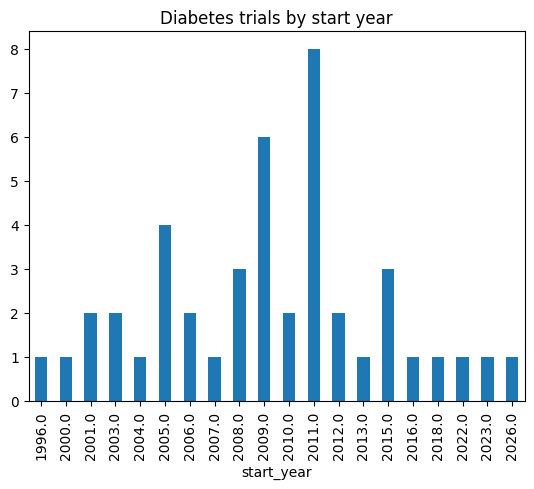

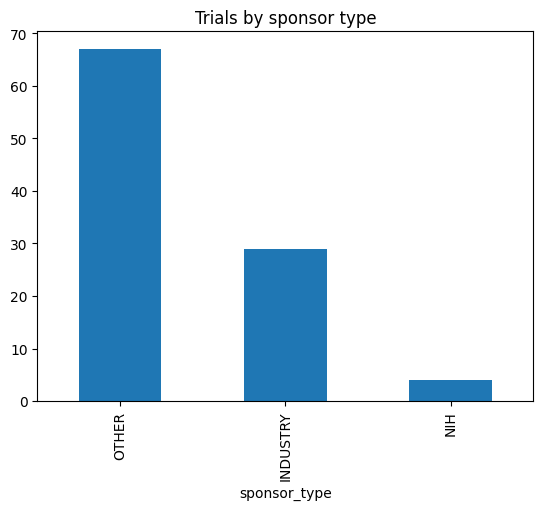

In [ ]:
import matplotlib.pyplot as plt

df["start_year"] = pd.to_datetime(df["start_date"], errors="coerce").dt.year

df["start_year"].value_counts().sort_index().plot(kind="bar", title="Diabetes trials by start year")
plt.show()

df["sponsor_type"].value_counts().plot(kind="bar", title="Trials by sponsor type")
plt.show()

In [ ]:
"""
Step 2: fetch more data from ClinicalTrials.gov (API v2)
- follows pagination with nextPageToken
- loops over several conditions
- saves one combined CSV

Paste into a Colab cell (requests and pandas are pre-installed there).
"""

import time
import requests
import pandas as pd

API_URL = "https://clinicaltrials.gov/api/v2/studies"

CONDITIONS = ["diabetes", "obesity", "alzheimer", "breast cancer"]
PAGE_SIZE = 1000          # API maximum per page
MAX_PAGES_PER_CONDITION = 5  # keeps it to ~5,000 trials per condition; raise later if you want


def parse_study(study, condition):
    ps = study.get("protocolSection", {})
    ident = ps.get("identificationModule", {})
    status = ps.get("statusModule", {})
    design = ps.get("designModule", {})
    sponsor = ps.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {})
    locations = ps.get("contactsLocationsModule", {}).get("locations", [])

    return {
        "condition_query": condition,
        "nct_id": ident.get("nctId"),
        "title": ident.get("briefTitle"),
        "status": status.get("overallStatus"),
        "phases": ", ".join(design.get("phases", [])),
        "study_type": design.get("studyType"),
        "enrollment": design.get("enrollmentInfo", {}).get("count"),
        "sponsor": sponsor.get("name"),
        "sponsor_type": sponsor.get("class"),
        "start_date": status.get("startDateStruct", {}).get("date"),
        "countries": ", ".join(sorted({loc.get("country") for loc in locations if loc.get("country")})),
    }


def fetch_condition(condition):
    rows = []
    page_token = None

    for page in range(MAX_PAGES_PER_CONDITION):
        params = {"query.cond": condition, "pageSize": PAGE_SIZE, "format": "json"}
        if page_token:
            params["pageToken"] = page_token

        response = requests.get(API_URL, params=params, timeout=60)
        response.raise_for_status()
        data = response.json()

        studies = data.get("studies", [])
        rows.extend(parse_study(s, condition) for s in studies)
        print(f"{condition}: page {page + 1}, {len(studies)} trials (total {len(rows)})")

        page_token = data.get("nextPageToken")
        if not page_token:
            break
        time.sleep(0.5)  # be polite to the API

    return rows


all_rows = []
for condition in CONDITIONS:
    all_rows.extend(fetch_condition(condition))

df = pd.DataFrame(all_rows)

# Same trial can match several conditions: keep track, but also note duplicates
print(f"\nTotal rows: {len(df)}, unique trials: {df['nct_id'].nunique()}")
print(df.groupby("condition_query")["nct_id"].count())

df.to_csv("trials_multi.csv", index=False)
print("\nSaved to trials_multi.csv")

diabetes: page 1, 1000 trials (total 1000)
diabetes: page 2, 1000 trials (total 2000)
diabetes: page 3, 1000 trials (total 3000)
diabetes: page 4, 1000 trials (total 4000)
diabetes: page 5, 1000 trials (total 5000)
obesity: page 1, 1000 trials (total 1000)
obesity: page 2, 1000 trials (total 2000)
obesity: page 3, 1000 trials (total 3000)
obesity: page 4, 1000 trials (total 4000)
obesity: page 5, 1000 trials (total 5000)
alzheimer: page 1, 1000 trials (total 1000)
alzheimer: page 2, 1000 trials (total 2000)
alzheimer: page 3, 1000 trials (total 3000)
alzheimer: page 4, 1000 trials (total 4000)
alzheimer: page 5, 71 trials (total 4071)
breast cancer: page 1, 1000 trials (total 1000)
breast cancer: page 2, 1000 trials (total 2000)
breast cancer: page 3, 1000 trials (total 3000)
breast cancer: page 4, 1000 trials (total 4000)
breast cancer: page 5, 1000 trials (total 5000)

Total rows: 19071, unique trials: 18470
condition_query
alzheimer        4071
breast cancer    5000
diabetes        

In [ ]:
"""
Step 3: clean the data and check data quality.
Run after fetch_more_trials.py (expects trials_multi.csv).

Produces:
- trials_clean.csv          cleaned, de-duplicated dataset
- data_quality_report.csv   one row per check, so you can show it in the README/dashboard
"""

import pandas as pd

df = pd.read_csv("trials_multi.csv")
checks = []  # collect results for the data quality report


def log(check, value, note=""):
    checks.append({"check": check, "value": value, "note": note})
    print(f"{check}: {value} {note}")


log("Rows loaded", len(df))

# 1. Completeness: missing values per column
missing = df.isna().mean().mul(100).round(1)
for col, pct in missing.items():
    if pct > 0:
        log(f"Missing % - {col}", pct)

# 2. Uniqueness: the same trial can appear under several condition queries
dupes = df.duplicated(subset="nct_id").sum()
log("Duplicate trial IDs (across conditions)", dupes, "kept per condition, but de-duplicated for overall counts")

# Keep a condition-level table (one row per trial per condition) ...
df_by_condition = df.drop_duplicates(subset=["nct_id", "condition_query"]).copy()

# 3. Validity: dates come as 'YYYY-MM' or 'YYYY-MM-DD' -> parse both
df_by_condition["start_date_parsed"] = pd.to_datetime(
    df_by_condition["start_date"], errors="coerce", format="mixed"
)
bad_dates = df_by_condition["start_date"].notna() & df_by_condition["start_date_parsed"].isna()
log("Unparseable start dates", int(bad_dates.sum()))
df_by_condition["start_year"] = df_by_condition["start_date_parsed"].dt.year

future = df_by_condition["start_date_parsed"] > pd.Timestamp.today() + pd.DateOffset(years=2)
log("Start dates > 2 years in future", int(future.sum()), "check these manually")

# 4. Consistency: normalise phase labels (API gives e.g. 'PHASE1, PHASE2', 'NA', or empty)
phase_map = {
    "EARLY_PHASE1": "Early Phase 1",
    "PHASE1": "Phase 1",
    "PHASE1, PHASE2": "Phase 1/2",
    "PHASE2": "Phase 2",
    "PHASE2, PHASE3": "Phase 2/3",
    "PHASE3": "Phase 3",
    "PHASE4": "Phase 4",
    "NA": "Not applicable",
}
df_by_condition["phase_clean"] = df_by_condition["phases"].map(phase_map).fillna("Not specified")
log("Phase categories", df_by_condition["phase_clean"].nunique())

# 5. Validity: enrollment should be a non-negative number
df_by_condition["enrollment"] = pd.to_numeric(df_by_condition["enrollment"], errors="coerce")
log("Negative enrollment values", int((df_by_condition["enrollment"] < 0).sum()))
p99 = df_by_condition["enrollment"].quantile(0.99)
outliers = (df_by_condition["enrollment"] > p99).sum()
log("Enrollment outliers (> 99th percentile)", int(outliers), f"threshold = {p99:.0f}")

# 6. Consistency: tidy sponsor type labels
df_by_condition["sponsor_type"] = df_by_condition["sponsor_type"].fillna("UNKNOWN").str.upper()
log("Sponsor type categories", ", ".join(sorted(df_by_condition["sponsor_type"].unique())))

# Save outputs
df_by_condition.to_csv("trials_clean.csv", index=False)
pd.DataFrame(checks).to_csv("data_quality_report.csv", index=False)
print(f"\nSaved trials_clean.csv ({len(df_by_condition)} rows) and data_quality_report.csv")

Rows loaded: 19071 
Missing % - phases: 62.6 
Missing % - enrollment: 1.0 
Missing % - start_date: 0.5 
Missing % - countries: 9.0 
Duplicate trial IDs (across conditions): 601 kept per condition, but de-duplicated for overall counts
Unparseable start dates: 0 
Start dates > 2 years in future: 3 check these manually
Phase categories: 8 
Negative enrollment values: 0 
Enrollment outliers (> 99th percentile): 189 threshold = 16632
Sponsor type categories: FED, INDIV, INDUSTRY, NETWORK, NIH, OTHER, OTHER_GOV, UNKNOWN 

Saved trials_clean.csv (19071 rows) and data_quality_report.csv


In [ ]:
"""
Step 4: store the cleaned data in a small SQL database (SQLite)
and run a few example queries.
Run after clean_and_check.py (expects trials_clean.csv).

SQLite is built into Python: no server, no install. The whole database
is one file (trials.db) you can commit to GitHub or open in a tool like
DB Browser for SQLite.
"""

import sqlite3
import pandas as pd

df = pd.read_csv("trials_clean.csv")

conn = sqlite3.connect("trials.db")

# --- Table 1: one row per trial (de-duplicated) -------------------------
trials = (
    df.drop_duplicates(subset="nct_id")
      [["nct_id", "title", "status", "phase_clean", "study_type",
        "enrollment", "sponsor", "sponsor_type", "start_date", "start_year", "countries"]]
)
trials.to_sql("trials", conn, if_exists="replace", index=False)

# --- Table 2: which condition query each trial matched -------------------
# (a trial can belong to several conditions -> separate link table)
trial_conditions = df[["nct_id", "condition_query"]].drop_duplicates()
trial_conditions.to_sql("trial_conditions", conn, if_exists="replace", index=False)

# --- Table 3: the data quality report, so it lives next to the data -----
pd.read_csv("data_quality_report.csv").to_sql("data_quality", conn, if_exists="replace", index=False)

# Index for faster joins
conn.execute("CREATE INDEX IF NOT EXISTS idx_tc_nct ON trial_conditions(nct_id)")
conn.commit()

print("Tables created:")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))

# --- Example queries ------------------------------------------------------
print("\nTrials per condition and phase:")
print(pd.read_sql("""
    SELECT c.condition_query, t.phase_clean, COUNT(*) AS n_trials
    FROM trials t
    JOIN trial_conditions c ON t.nct_id = c.nct_id
    GROUP BY c.condition_query, t.phase_clean
    ORDER BY c.condition_query, n_trials DESC
""", conn))

print("\nTop 10 industry sponsors:")
print(pd.read_sql("""
    SELECT sponsor, COUNT(*) AS n_trials
    FROM trials
    WHERE sponsor_type = 'INDUSTRY'
    GROUP BY sponsor
    ORDER BY n_trials DESC
    LIMIT 10
""", conn))

print("\nNew trials per year since 2015, by condition:")
print(pd.read_sql("""
    SELECT c.condition_query, t.start_year, COUNT(*) AS n_trials
    FROM trials t
    JOIN trial_conditions c ON t.nct_id = c.nct_id
    WHERE t.start_year >= 2015
    GROUP BY c.condition_query, t.start_year
    ORDER BY c.condition_query, t.start_year
""", conn))

conn.close()
print("\nSaved database to trials.db")

Tables created:
               name
0            trials
1  trial_conditions
2      data_quality

Trials per condition and phase:
   condition_query    phase_clean  n_trials
0        alzheimer  Not specified      2350
1        alzheimer        Phase 2       575
2        alzheimer        Phase 1       476
3        alzheimer        Phase 3       300
4        alzheimer        Phase 4       139
5        alzheimer      Phase 1/2       105
6        alzheimer  Early Phase 1        66
7        alzheimer      Phase 2/3        60
8    breast cancer  Not specified      2568
9    breast cancer        Phase 2      1039
10   breast cancer        Phase 1       464
11   breast cancer        Phase 3       416
12   breast cancer      Phase 1/2       274
13   breast cancer        Phase 4       119
14   breast cancer  Early Phase 1        71
15   breast cancer      Phase 2/3        49
16        diabetes  Not specified      3120
17        diabetes        Phase 3       456
18        diabetes        Phase 4  

In [ ]:
from google.colab import files
files.download("trials.db")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>